In [4]:
import yaml
import sys
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as pl
import seaborn as sns
from pathlib import Path
from tqdm.auto import tqdm
import PyComplexHeatmap as pch

from matplotlib import rcParams
# Type 2/TrueType fonts
rcParams['pdf.fonttype'] = 42
rcParams['ps.fonttype'] = 42
# Arial font
rcParams['font.sans-serif'] = "Arial"
rcParams['font.family'] = "sans-serif"

# Remove warning, we like to live dangerously
warnings.filterwarnings("ignore")

# load functions from ../utils
sys.path.append('../utils')
from utils import annotate_essentiality

# Get config settings
with open('../configuration/config.yaml', "r") as file:
    config = yaml.load(file, Loader=yaml.FullLoader)
cell_line_dict=config['cell_lines']  # Syntax: sym_cellline_replicate
cell_line_colors=config['cell_line_colors']

# Evidence of sample swap

In [5]:
# samples were swapped: sym-H1975-Rep1-TP6 with sym-H1975-Rep2-TP6
# Or in original sample names: sym-01-01-TP6 with sym-01-02-TP6

In [ ]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'SYM101_counts.csv', index_col=0)
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]

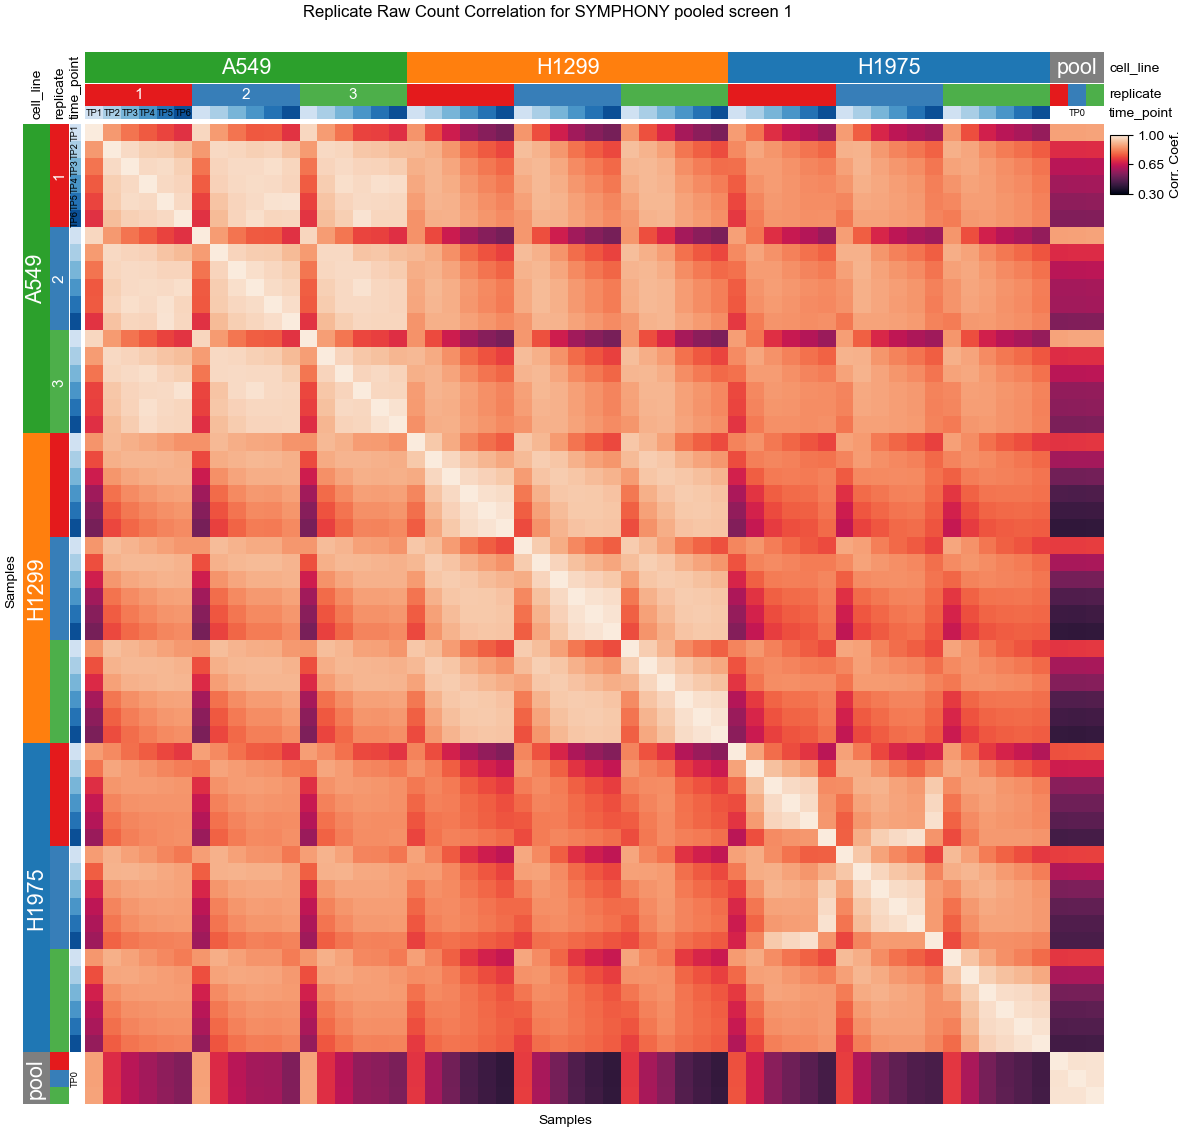

In [7]:
# Calculate pairwise correlations between samples
pairwise_correlations = pd.DataFrame(index=sample_names, columns=sample_names, dtype=float)
for i in sample_names:
    for j in sample_names:
        pairwise_correlations.loc[i, j] = np.corrcoef(df.loc[:, i], df.loc[:, j])[0, 1]

# Prepare annotation
cell_line = pd.Series({x: cell_line_dict[int(x.split('-')[1])] if x.split('-')[1]!='pool' else 'pool' for x in sample_names})
replicate = pd.Series({x: x.split('-')[2][-1] if 'pool' not in x else x.split('-')[-1] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] if 'pool' not in x else 'TP0' for x in sample_names})
order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 1, 2]).index  # sort by time before replicate

# select and reorder
data = pairwise_correlations.loc[order, order]

# Create the colormap
from matplotlib.colors import LinearSegmentedColormap
cmap = sns.color_palette('Blues', as_cmap=True)
colors = [cmap(x) for x in np.linspace(0.2, 0.9, 7)] + [(1, 1, 1, 1)]  # white for TP0
time_cmap = LinearSegmentedColormap.from_list("gradual_colormap", colors, N=7)

annot_kwargs = dict(
    cell_line=pch.anno_simple(cell_line.loc[order], add_text=True, height=7, colors=cell_line_colors),
    replicate=pch.anno_simple(replicate.loc[order], add_text=True, height=5),
    time_point=pch.anno_simple(time_point.loc[order], add_text=True, height=3, cmap=time_cmap),
    verbose=0, plot_legend=False
)
top_ha = pch.HeatmapAnnotation(axis=1, **annot_kwargs)
left_ha = pch.HeatmapAnnotation(axis=0, **annot_kwargs)

pl.figure(figsize=(14, 12))
cm = pch.ClusterMapPlotter(
    data=data, left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmin=0.3, vmax=1,
    legend_kws=dict(label='Corr. Coef.'),
    xlabel="Samples", ylabel='Samples', legend_hpad=0,
    verbose=0
)
pl.suptitle('Replicate Raw Count Correlation for SYMPHONY pooled screen 1', y=0.92)
# pl.savefig('../results/qc_plots/qc_correlation_heatmap_simple.png', dpi=300)
# pl.savefig('../results/qc_plots/qc_correlation_heatmap_simple.pdf', dpi=300, bbox_inches='tight')
# pairwise_correlations.to_csv('../results/qc_plots/qc_correlation_source_data.csv')
pl.show()

# Correct sample swap

In [8]:
df = pd.read_csv(Path(config['TEMPDIR']) / 'SYM101_counts.csv', index_col=0)
df = df.rename({'sym-01-01-TP6' : 'sym-01-02-TP6', 'sym-01-02-TP6' : 'sym-01-01-TP6'}, axis=1)  # revert sample swap
sample_names = np.sort(df.columns[12:])
pools = ['Sym-pool-1-3', 'Sym-pool-1-1', 'Sym-pool-1-2']
pools = np.sort(pools)
controls = [x for x in df.index if 'control' in x.lower()]

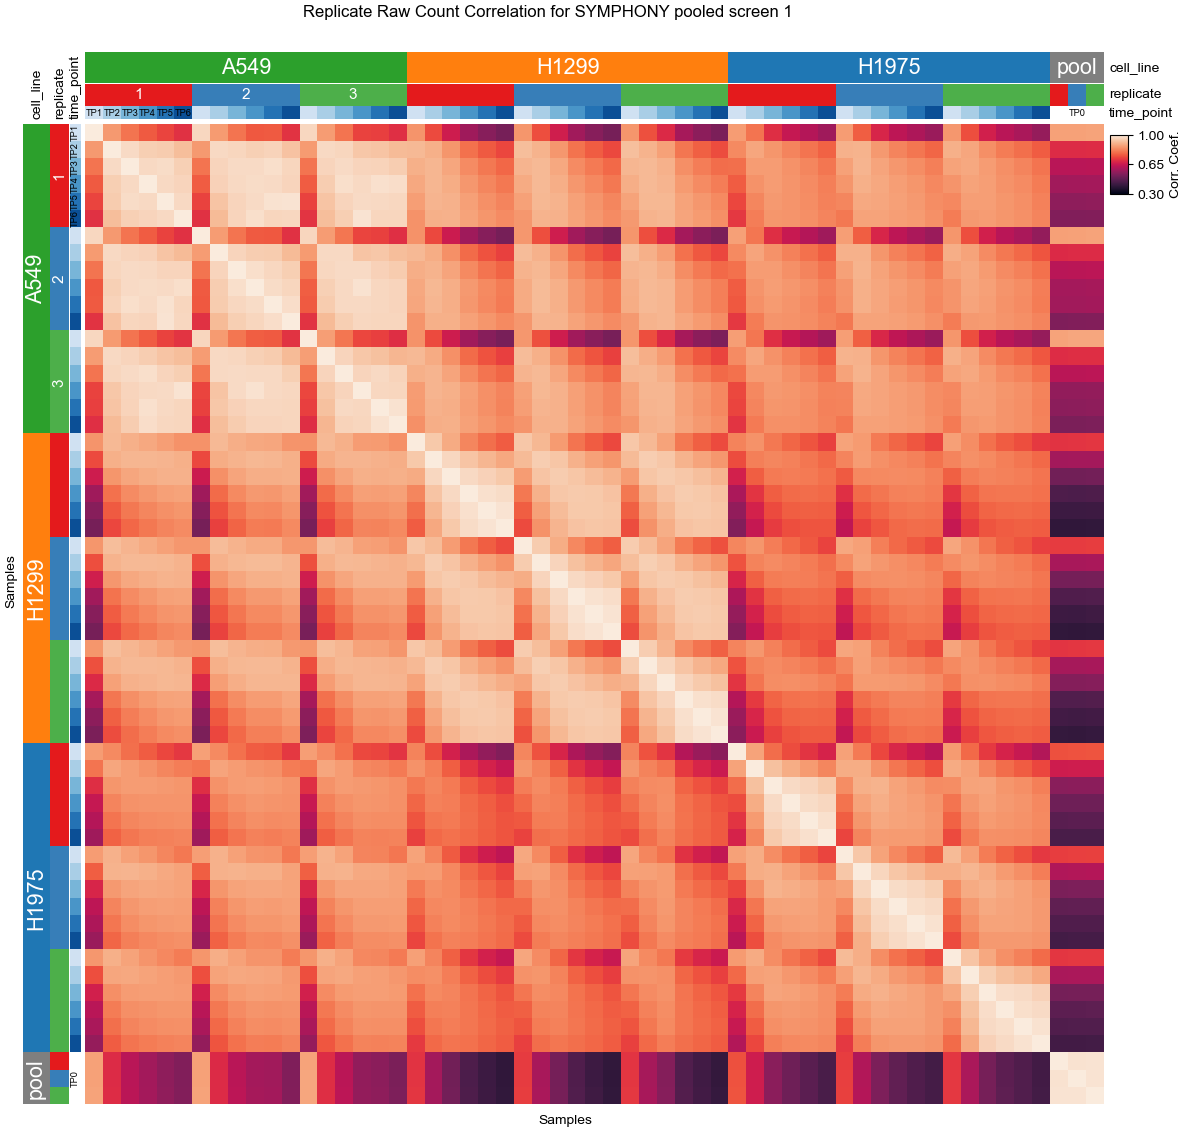

In [9]:
# Calculate pairwise correlations between samples
pairwise_correlations = pd.DataFrame(index=sample_names, columns=sample_names, dtype=float)
for i in sample_names:
    for j in sample_names:
        pairwise_correlations.loc[i, j] = np.corrcoef(df.loc[:, i], df.loc[:, j])[0, 1]

# Prepare annotation
cell_line = pd.Series({x: cell_line_dict[int(x.split('-')[1])] if x.split('-')[1]!='pool' else 'pool' for x in sample_names})
replicate = pd.Series({x: x.split('-')[2][-1] if 'pool' not in x else x.split('-')[-1] for x in sample_names})
time_point = pd.Series({x: x.split('-')[3].split('_')[0] if 'pool' not in x else 'TP0' for x in sample_names})
order = pd.concat([cell_line, replicate, time_point], axis=1).sort_values([0, 1, 2]).index  # sort by time before replicate

# select and reorder
data = pairwise_correlations.loc[order, order]

# Create the colormap
from matplotlib.colors import LinearSegmentedColormap
cmap = sns.color_palette('Blues', as_cmap=True)
colors = [cmap(x) for x in np.linspace(0.2, 0.9, 7)] + [(1, 1, 1, 1)]  # white for TP0
time_cmap = LinearSegmentedColormap.from_list("gradual_colormap", colors, N=7)

annot_kwargs = dict(
    cell_line=pch.anno_simple(cell_line.loc[order], add_text=True, height=7, colors=cell_line_colors),
    replicate=pch.anno_simple(replicate.loc[order], add_text=True, height=5),
    time_point=pch.anno_simple(time_point.loc[order], add_text=True, height=3, cmap=time_cmap),
    verbose=0, plot_legend=False
)
top_ha = pch.HeatmapAnnotation(axis=1, **annot_kwargs)
left_ha = pch.HeatmapAnnotation(axis=0, **annot_kwargs)

pl.figure(figsize=(14, 12))
cm = pch.ClusterMapPlotter(
    data=data, left_annotation=left_ha, top_annotation=top_ha,
    row_cluster=False, col_cluster=False,
    label='beta', row_dendrogram=False, col_dendrogram=False,
    legend_gap=7, rasterized=True, cmap='rocket', vmin=0.3, vmax=1,
    legend_kws=dict(label='Corr. Coef.'),
    xlabel="Samples", ylabel='Samples', legend_hpad=0,
    verbose=0
)
pl.suptitle('Replicate Raw Count Correlation for SYMPHONY pooled screen 1', y=0.92)
# pl.savefig('../results/qc_plots/qc_correlation_heatmap_simple.png', dpi=300)
# pl.savefig('../results/qc_plots/qc_correlation_heatmap_simple.pdf', dpi=300, bbox_inches='tight')
# pairwise_correlations.to_csv('../results/qc_plots/qc_correlation_source_data.csv')
pl.show()

In [ ]:
# df.to_csv(Path(config['TEMPDIR']) / 'SYM101_counts_corrected.csv')